**Karib Fiyaz - 23201612**

**Zafra Musarrat Islam - 23241010**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

**DATASET UPLOAD**

In [ ]:
df = pd.read_csv('mushroom_dataset.csv', delimiter=';')
df.head()

,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,...,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,...,s,y,w,u,w,t,p,NaN,d,w


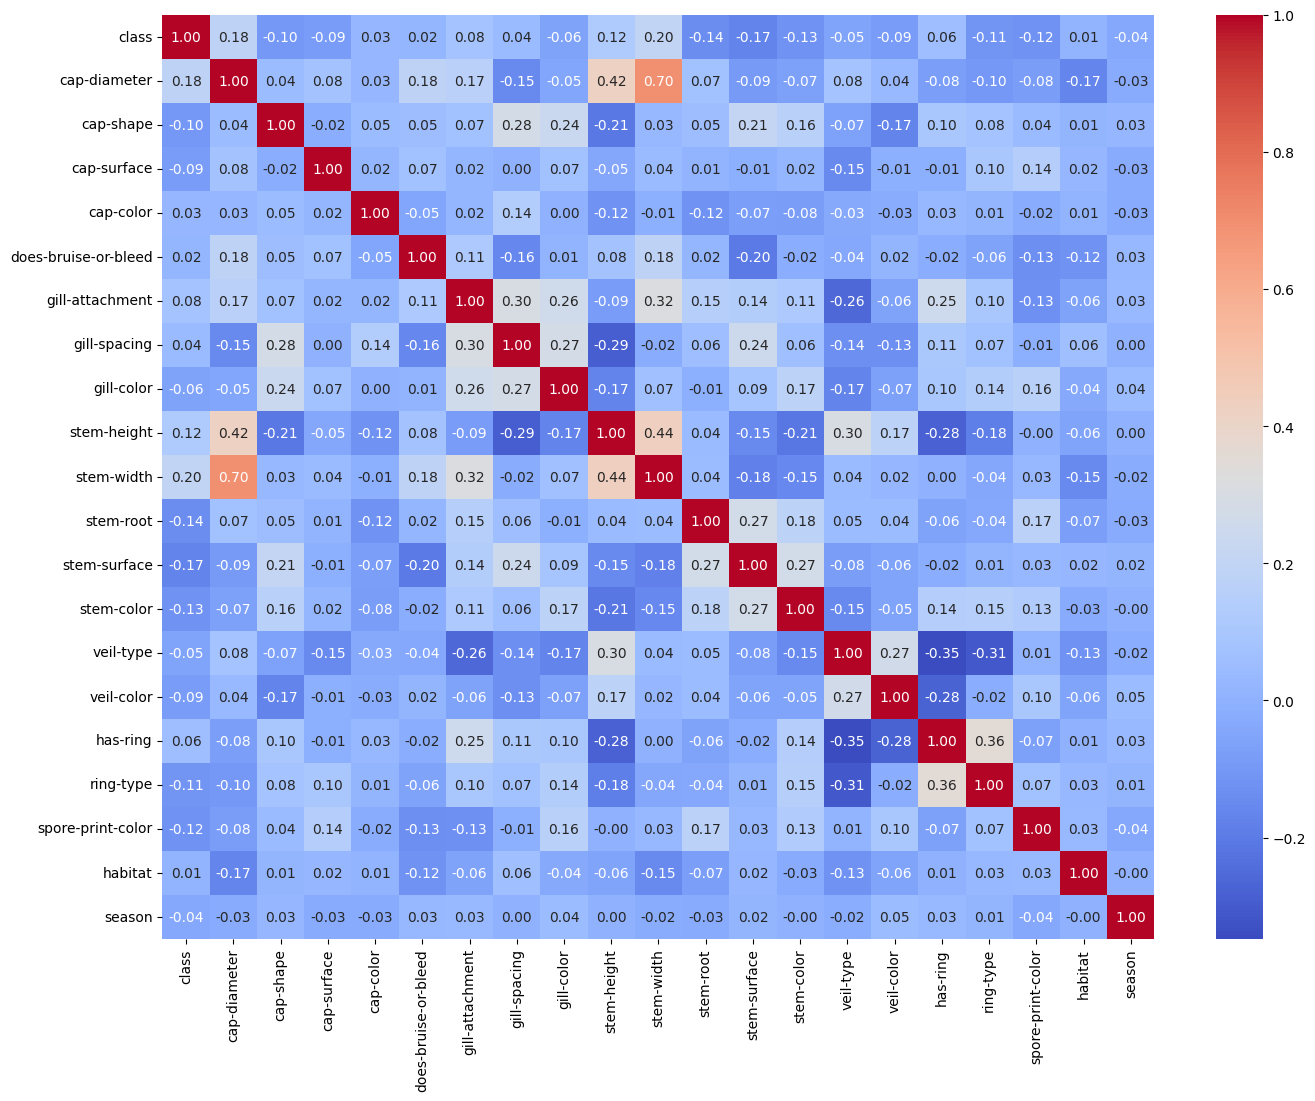

In [ ]:
df_encoded = df.apply(lambda x: x.factorize()[0] if x.dtype == 'object' else x)
corr = df_encoded.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

/tmp/ipykernel_2484/2219900644.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=df, palette='viridis')


Class Counts:
class
p    33888
e    27181
Name: count, dtype: int64


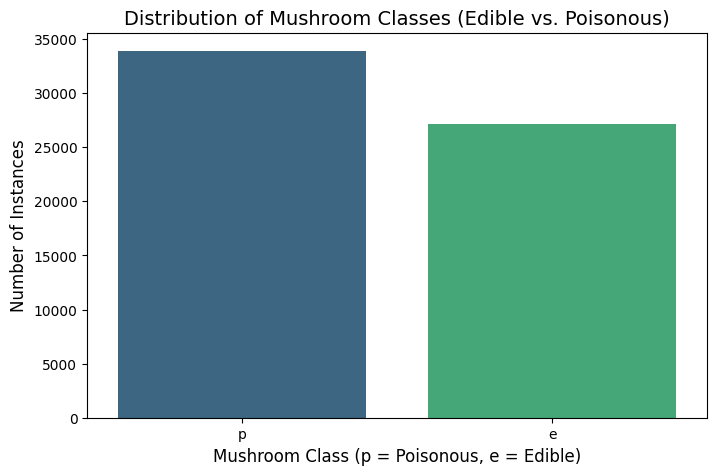

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='class', data=df, palette='viridis')
plt.title('Distribution of Mushroom Classes (Edible vs. Poisonous)', fontsize=14)
plt.xlabel('Mushroom Class (p = Poisonous, e = Edible)', fontsize=12)
plt.ylabel('Number of Instances', fontsize=12)
class_counts = df['class'].value_counts()
print("Class Counts:")
print(class_counts)
plt.show()

**EDA (Exploratory Data Analysis)**

In [ ]:
df.shape

(61069, 21)

In [ ]:
df.isnull().sum()

,0
class,0
cap-diameter,0
cap-shape,0
cap-surface,14120
cap-color,0
does-bruise-or-bleed,0
gill-attachment,9884
gill-spacing,25063
gill-color,0
stem-height,0


**DATASET PRE PROCESSING**

In [ ]:

df.drop(['stem-root', 'veil-type', 'veil-color', 'spore-print-color'], axis=1, inplace=True)

In [ ]:
df.drop(['cap-diameter','season'],axis=1,inplace=True)



In [ ]:
df.drop(['cap-color','gill-color','stem-color'],axis=1,inplace=True)

In [ ]:
df.drop(['ring-type','stem-height','stem-width'],axis=1,inplace=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
df.isnull().sum()

,0
class,0
cap-shape,0
cap-surface,14120
does-bruise-or-bleed,0
gill-attachment,9884
gill-spacing,25063
stem-surface,38124
has-ring,0
habitat,0


In [ ]:
from sklearn.impute import SimpleImputer


In [ ]:
imp = SimpleImputer(strategy='most_frequent')

cols = ['cap-surface', 'gill-attachment', 'gill-spacing', 'stem-surface']

df.loc[:, cols] = imp.fit_transform(df[cols])

In [ ]:
df.nunique()

,0
class,2
cap-shape,7
cap-surface,11
does-bruise-or-bleed,2
gill-attachment,7
gill-spacing,3
stem-surface,8
has-ring,2
habitat,8


**Dataset Encoding**

In [ ]:
# Categorical Encoding  0/1 binary

le=LabelEncoder()
df["class"]=le.fit_transform(df["class"])
df["does-bruise-or-bleed"]=le.fit_transform(df["does-bruise-or-bleed"])
df["has-ring"]=le.fit_transform(df["has-ring"])

In [ ]:
# One Hot Encoding

cols_to_encode = [
    'cap-shape',
    'cap-surface',
    'gill-attachment',
    'gill-spacing',
    'stem-surface',
    'habitat'
]

df= pd.get_dummies(df, columns=cols_to_encode)

In [ ]:
df.head()

,class,does-bruise-or-bleed,has-ring,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_o,cap-shape_p,cap-shape_s,cap-shape_x,...,stem-surface_t,stem-surface_y,habitat_d,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,1,0,1,False,False,False,False,False,False,True,...,False,True,True,False,False,False,False,False,False,False
1,1,0,1,False,False,False,False,False,False,True,...,False,True,True,False,False,False,False,False,False,False
2,1,0,1,False,False,False,False,False,False,True,...,False,True,True,False,False,False,False,False,False,False
3,1,0,1,False,False,True,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
4,1,0,1,False,False,False,False,False,False,True,...,False,True,True,False,False,False,False,False,False,False


In [ ]:
df = df.astype(int)

**TRAIN-TEST SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop('class', axis=1)
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**STANDARDIZATION**

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
sc= StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

**Model Training**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [ ]:
k=KNeighborsClassifier(n_neighbors=50)
k.fit(X_train,y_train)
y_pred_knn = k.predict(X_test)
kn_acc=accuracy_score(y_test, y_pred_knn)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.9209104306533487


In [ ]:
from sklearn.linear_model import LogisticRegression
#Logistic Regression
l=LogisticRegression(max_iter=1000)
l.fit(X_train,y_train)
y_pred_lr = l.predict(X_test)
lr_acc=accuracy_score(y_test, y_pred_lr)
print("lr Accuracy:", accuracy_score(y_test, y_pred_lr))

lr Accuracy: 0.7251514655313575


In [ ]:
#Neural Network
from sklearn.neural_network import MLPClassifier
nn = MLPClassifier(hidden_layer_sizes=(50,50,50,50), max_iter=500)
nn.fit(X_train, y_train)

y_pred_nn = nn.predict(X_test)
nn_acc=accuracy_score(y_test, y_pred_nn)

print("NN Accuracy:", accuracy_score(y_test, y_pred_nn))

NN Accuracy: 0.9226297691174062


In [ ]:
#DECISION TREE
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

dt_acc = accuracy_score(y_test, y_pred_dt)

print("DT Accuracy:", accuracy_score(y_test, y_pred_dt))

DT Accuracy: 0.9230391354183723


**COMPARISON**

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.cluster import KMeans

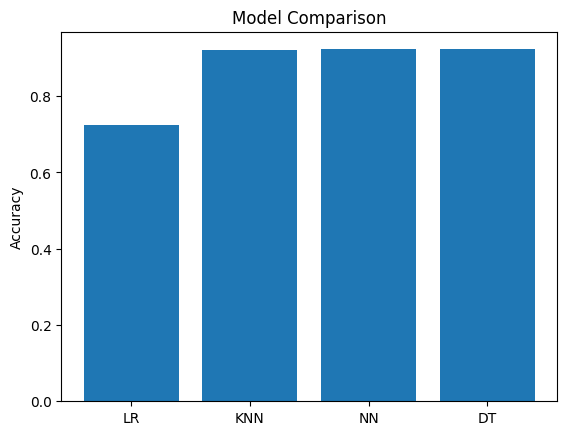

[0.7251514655313575, 0.9209104306533487, 0.9226297691174062, 0.9230391354183723]


In [ ]:
#BAR CHART
models = ['LR', 'KNN', 'NN','DT']
scores = [lr_acc,kn_acc,nn_acc,dt_acc]

plt.bar(models, scores)
plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.show()

print(scores)

In [ ]:

print("Logistic Regression\n", classification_report(y_test, y_pred_lr))
print("KNN\n", classification_report(y_test, y_pred_knn))
print("Neural Network\n", classification_report(y_test, y_pred_nn))
print("Decision Tree\n", classification_report(y_test, y_pred_dt))

Logistic Regression
               precision    recall  f1-score   support

           0       0.72      0.62      0.66      5374
           1       0.73      0.81      0.77      6840

    accuracy                           0.73     12214
   macro avg       0.72      0.71      0.72     12214
weighted avg       0.72      0.73      0.72     12214

KNN
               precision    recall  f1-score   support

           0       0.90      0.92      0.91      5374
           1       0.94      0.92      0.93      6840

    accuracy                           0.92     12214
   macro avg       0.92      0.92      0.92     12214
weighted avg       0.92      0.92      0.92     12214

Neural Network
               precision    recall  f1-score   support

           0       0.91      0.92      0.91      5374
           1       0.93      0.93      0.93      6840

    accuracy                           0.92     12214
   macro avg       0.92      0.92      0.92     12214
weighted avg       0.92      0.9

CONFUSION MATRIX

<Axes: >

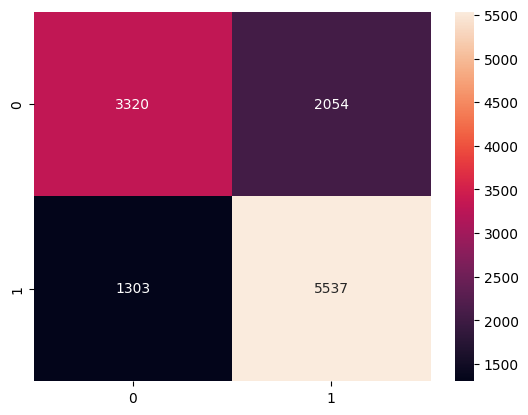

In [ ]:
cm1 = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm1, annot=True, fmt='d')

<Axes: >

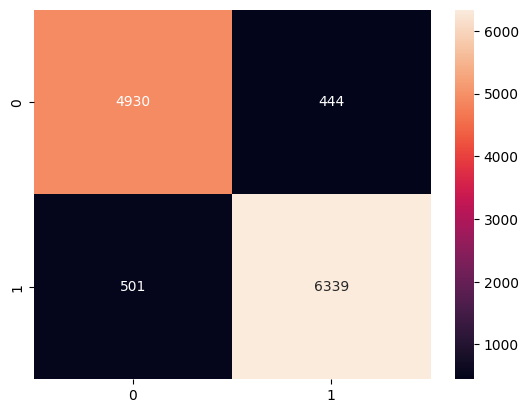

In [ ]:
cm2 = confusion_matrix(y_test, y_pred_nn)
sns.heatmap(cm2, annot=True, fmt='d')

<Axes: >

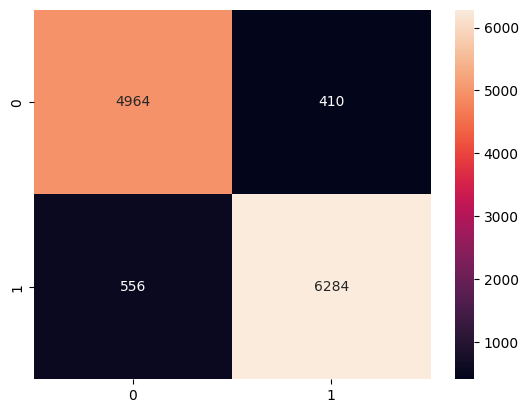

In [ ]:
cm3 = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm3, annot=True, fmt='d')

<Axes: >

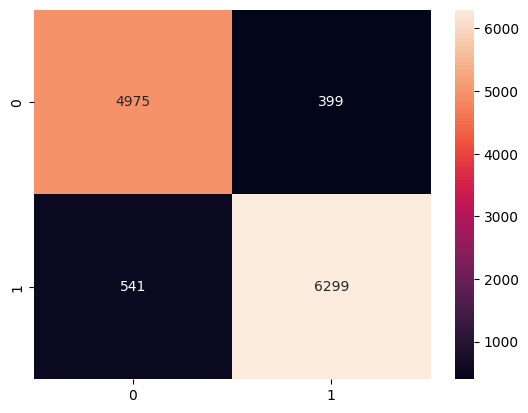

In [ ]:
cm4 = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm4, annot=True, fmt='d')

ROC and AUC CURVE

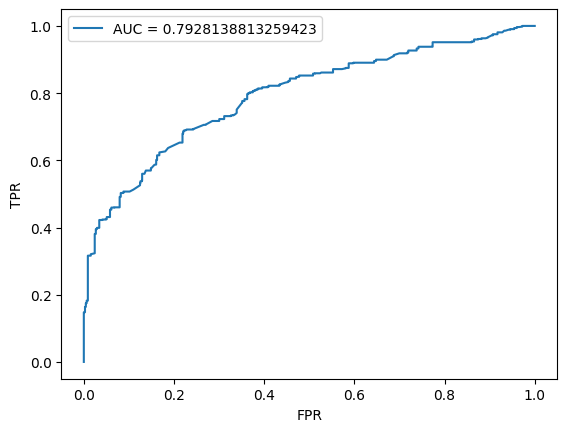

In [ ]:
y_prob = l.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

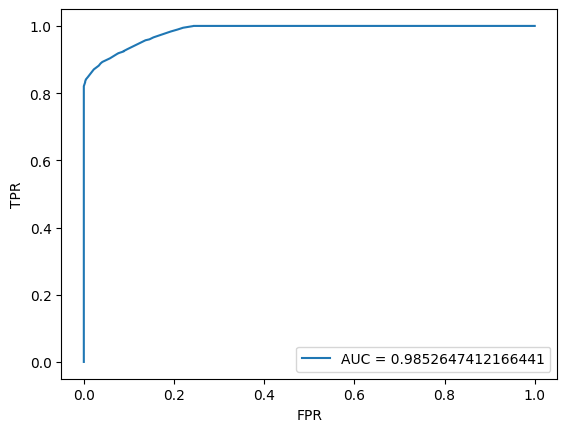

In [ ]:
y_prob = k.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

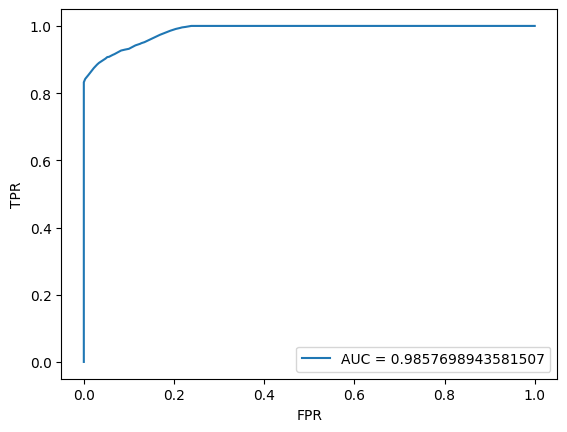

In [ ]:
y_prob = nn.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

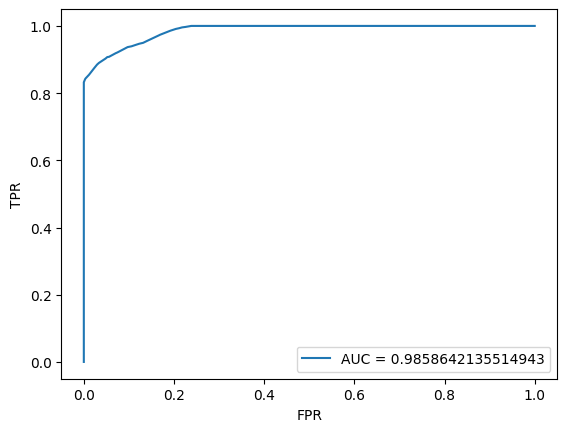

In [ ]:
y_prob = dt.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

K MEANS CLUSTERING

In [ ]:
from sklearn.cluster import KMeans

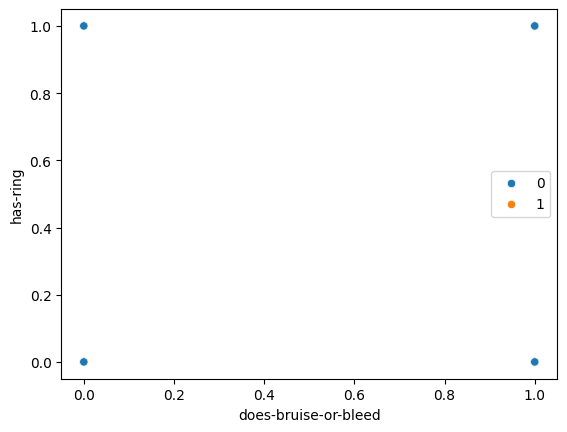

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X)

clusters = kmeans.labels_

sns.scatterplot(
    x=X.iloc[:,0],
    y=X.iloc[:,1],
    hue=clusters
)
plt.show()